In [ ]:
import anndata, numpy as np, pandas as pd 
import glob,os 

In [2]:
adata = anndata.read_h5ad(r'/mnt/xuisebnas2/Lab/Bereket_SEA_AD_analysis/SEA_AD_dataset/combined_anndata_object/SEAAD_MTG_MERFISH.2024-12-11.h5ad')
adata

AnnData object with n_obs × n_vars = 1887729 × 180
    obs: 'Donor ID', 'Sex', 'Gender', 'Age at Death', 'Race (choice=White)', 'Race (choice=Black/ African American)', 'Race (choice=Asian)', 'Race (choice=American Indian/ Alaska Native)', 'Race (choice=Native Hawaiian or Pacific Islander)', 'Race (choice=Unknown or unreported)', 'Race (choice=Other)', 'specify other race', 'Hispanic/Latino', 'Highest level of education', 'Years of education', 'PMI', 'Fresh Brain Weight', 'Brain pH', 'Overall AD neuropathological Change', 'Thal', 'Braak', 'CERAD score', 'Overall CAA Score', 'Highest Lewy Body Disease', 'Total Microinfarcts (not observed grossly)', 'Total microinfarcts in screening sections', 'Atherosclerosis', 'Arteriolosclerosis', 'LATE', 'Cognitive Status', 'Last CASI Score', 'Interval from last CASI in months', 'Last MMSE Score', 'Interval from last MMSE in months', 'Last MOCA Score', 'Interval from last MOCA in months', 'APOE4 Status', 'Primary Study Name', 'Secondary Study Name', 

In [3]:
adata.obs.columns

Index(['Donor ID', 'Sex', 'Gender', 'Age at Death', 'Race (choice=White)',
       'Race (choice=Black/ African American)', 'Race (choice=Asian)',
       'Race (choice=American Indian/ Alaska Native)',
       'Race (choice=Native Hawaiian or Pacific Islander)',
       'Race (choice=Unknown or unreported)', 'Race (choice=Other)',
       'specify other race', 'Hispanic/Latino', 'Highest level of education',
       'Years of education', 'PMI', 'Fresh Brain Weight', 'Brain pH',
       'Overall AD neuropathological Change', 'Thal', 'Braak', 'CERAD score',
       'Overall CAA Score', 'Highest Lewy Body Disease',
       'Total Microinfarcts (not observed grossly)',
       'Total microinfarcts in screening sections', 'Atherosclerosis',
       'Arteriolosclerosis', 'LATE', 'Cognitive Status', 'Last CASI Score',
       'Interval from last CASI in months', 'Last MMSE Score',
       'Interval from last MMSE in months', 'Last MOCA Score',
       'Interval from last MOCA in months', 'APOE4 Status',
 

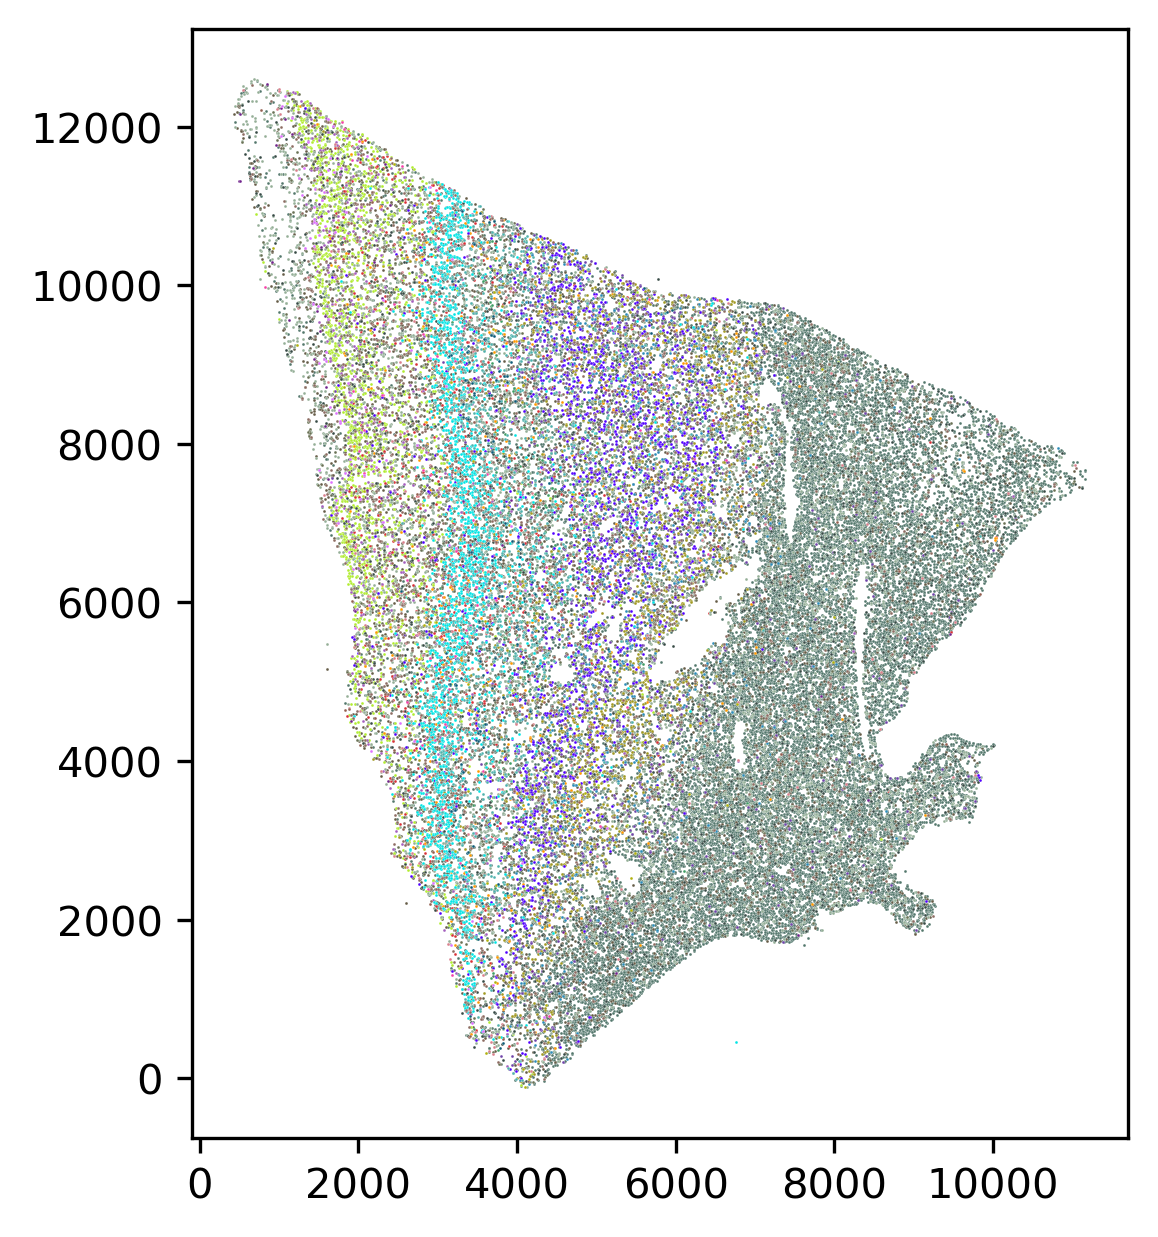

In [32]:
import matplotlib.pyplot as plt 
import seaborn as sns 
color_cmap = dict(zip(adata.obs.Subclass.cat.categories, adata.uns['subclass_colors']))
keep_section = adata.obs['Specimen Barcode'] == '1217500585'
fig, ax = plt.subplots(1,1,dpi = 300)
for celltype_ in adata.obs['Subclass'].unique():
    keep_celltype = adata.obs['Subclass'] == celltype_
    sns.scatterplot(x = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,0],
                     y = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,1], s = 0.5, c = color_cmap[celltype_])
# ax.set_axis_off()
ax.set_aspect('equal')
plt.show()

In [ ]:
def get_communityComposition(adata,cellType_resolution = 'Group_name',clustering_re = 0.1,radius = 150,n_neighbors = 10):
    # Create a KD tree using the spatial position of cells.
    # then query neighoring cells within specific radius (e.g. radius of 150 um) 

    from scipy.spatial import KDTree
    import numpy as np
    from tqdm import tqdm
    import scanpy as sc 
    import scipy
    from tqdm import tqdm 

    # construct the compostion matrix
    X_spatial = adata.obsm['X_spatial_raw']
    ii =scipy.spatial.KDTree(X_spatial).query_ball_point(X_spatial, r = 200)
    unq_subclass, subclass_idx = np.unique(adata.obs[cellType_resolution], return_inverse=True)
    Mcells = np.zeros((len(adata),len(unq_subclass)))
    for cell_idx,ii_ in tqdm(enumerate(ii), desc = 'adding counts'):
        np.add.at(Mcells[cell_idx], subclass_idx[ii_],1)
    print('constructed compostion matix .......')
    mdata_subset = sc.AnnData(Mcells)
    mdata_subset.obsm['X_spatial_raw'] = X_spatial # akeep track of the spatial information 
    print('Running clustering...')
    sc.pp.neighbors(mdata_subset, n_neighbors=n_neighbors, use_rep='X')
    print('Constructed neighborhood graph...')
    sc.tl.umap(mdata_subset,random_state=0,min_dist=0.1)
    print('done with umap...')
    sc.tl.leiden(mdata_subset,resolution=clustering_re)
    print('done with leiden cluster...')
    cmap = ["#e6194B", "#3cb44b", "#ffe119", "#4363d8", "#f58231", "#911eb4", "#42d4f4", "#f032e6", "#bfef45",
        "#fabed4", "#469990", "#dcbeff", "#9A6324", "#fffac8", "#800000", "#aaffc3", "#808000", "#ffd8b1",
        "#000075", "#a9a9a9"]
    mdata_subset.uns['cmap']=cmap
    return mdata_subset.copy()

In [63]:
subadata = adata[adata.obs['Specimen Barcode'] == '1217500585'].copy()
madata = get_communityComposition(subadata,cellType_resolution = 'Subclass',clustering_re = 0.15,radius = 150,n_neighbors = 15)

adding counts: 61893it [00:00, 89311.16it/s]


In [57]:
madata

AnnData object with n_obs × n_vars = 61893 × 24
    obs: 'leiden'
    uns: 'neighbors', 'umap', 'leiden', 'cmap'
    obsm: 'X_spatial_raw', 'X_umap'
    obsp: 'distances', 'connectivities'

In [58]:
np.unique(madata.obs['leiden'])

array(['0', '1', '10', '2', '3', '4', '5', '6', '7', '8', '9'],
      dtype=object)

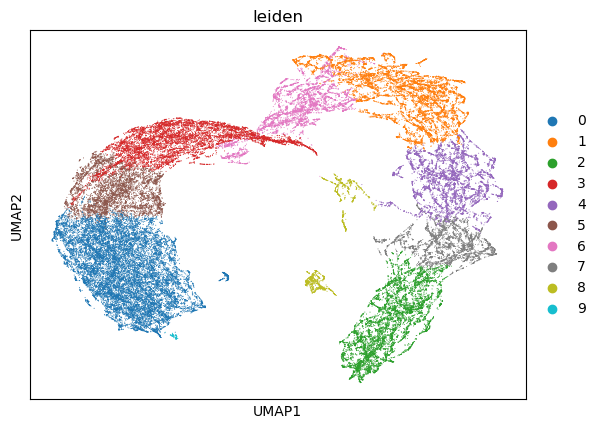

In [64]:
import scanpy as sc 
sc.pl.umap(madata, color = ['leiden'])

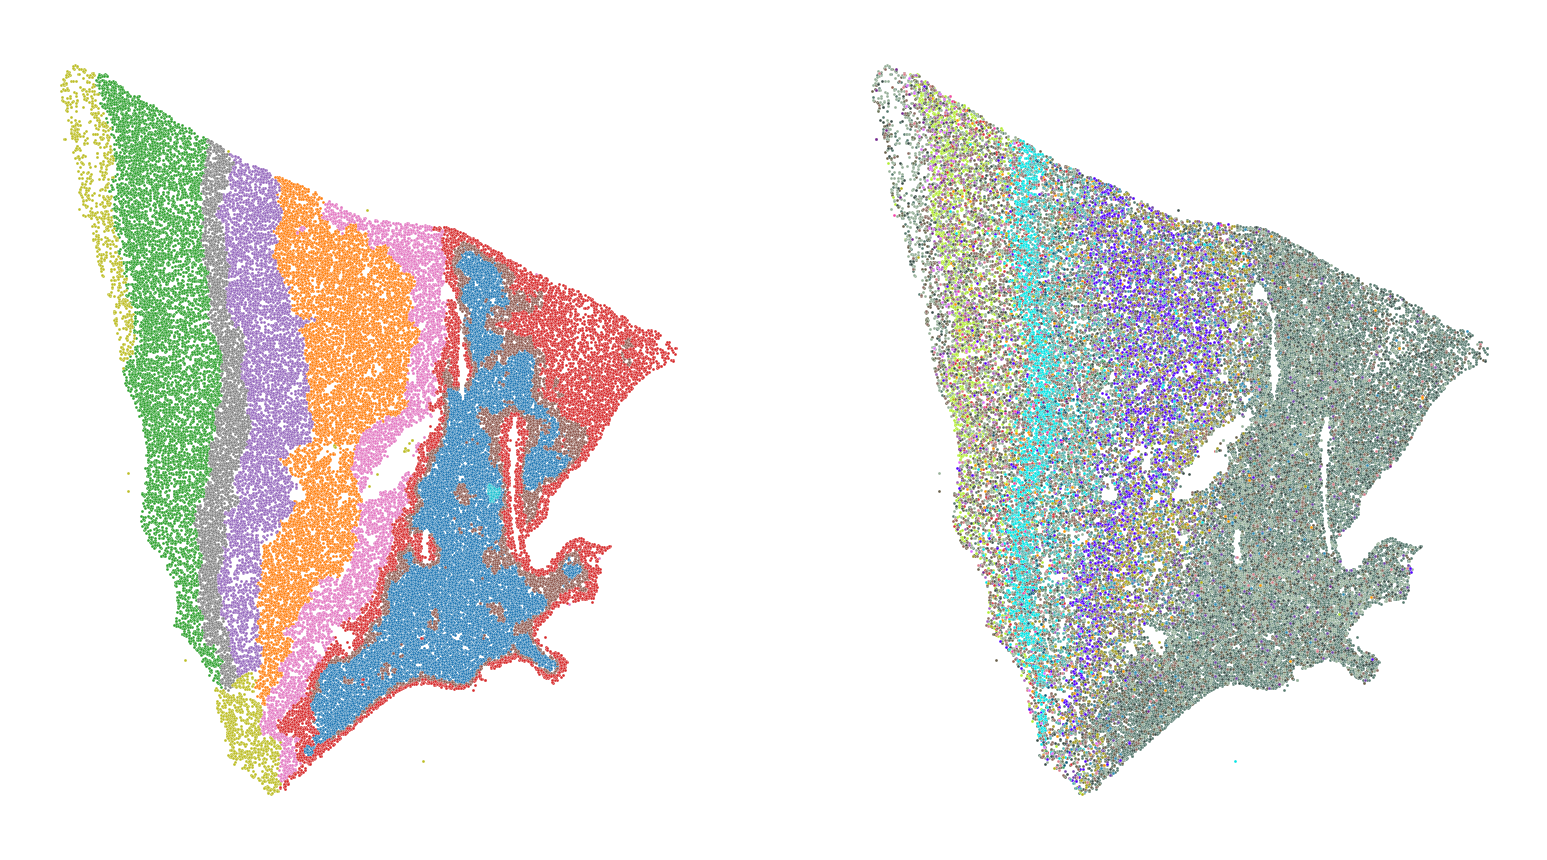

In [69]:
import matplotlib.pyplot as plt 
import seaborn as sns 
color_cmap = dict(zip(madata.obs.leiden.cat.categories, madata.uns['leiden_colors']))
# plot the community modules ++++++++++++++++++
fig, axs = plt.subplots(1,2,dpi = 300)
for ld in madata.obs['leiden'].unique():
    keep_ld = madata.obs['leiden'] == ld
    sns.scatterplot(x = madata[keep_ld].obsm['X_spatial_raw'][:,0],
                     y = madata[keep_ld].obsm['X_spatial_raw'][:,1], s = 0.5, c = color_cmap[ld], ax = axs[0])
axs[0].set_axis_off()
axs[0].set_aspect('equal')
# plot the cell-type spatial map ++++++++++++++ 

color_cmap = dict(zip(adata.obs.Subclass.cat.categories, adata.uns['subclass_colors']))
keep_section = adata.obs['Specimen Barcode'] == '1217500585'
for celltype_ in adata.obs['Subclass'].unique():
    keep_celltype = adata.obs['Subclass'] == celltype_
    sns.scatterplot(x = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,0],
                     y = adata[keep_section & keep_celltype].obsm['X_spatial_raw'][:,1], s = 0.5, c = color_cmap[celltype_], ax = axs[1])
axs[1].set_axis_off()
axs[1].set_aspect('equal')
plt.show()